# Notebook #03 — EDA, Correlation Analysis, Causal History Store (`T-3h`) & Gold Feature Matrix

### Nội dung cốt lõi
1. **Exploratory Data Analysis (EDA):** Trực quan hóa phân phối 3 lớp (`on_time / delayed / cancelled`), phân phối `delay_min`, tỷ lệ chậm theo hãng/sân bay, và bản đồ nhiệt chậm theo giờ (`Hourly Delay Heatmap`).
2. **Correlation & Association:** Tính đầy đủ **Pearson ($r$)**, **Spearman ($\rho$)** và **Cramér's V** cho biến phân loại.
3. **Causal History Store (`T-3h`) & Leakage Guardrails:** Tìm kiếm nhị phân `bisect_left` trên timestamp nanosecond `outcome_known_at < prediction_time`, chặn 9 cột hậu kiểm.
4. **Chronological Split 70 / 10 / 20:** `Train (9,503)` / `Val (1,353)` / `Test (2,714)`, xuất ma trận **66 đặc trưng sạch** + kiểm chứng Zero Lookahead.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from flight_delay.common.constants import FILE_GOLD, FORBIDDEN_POST_FLIGHT_COLUMNS, PROCESSED_DIR
from flight_delay.data_engineering.contracts import validate_gold_contract
from flight_delay.data_mining.feature_engineering.registry import FEATURE_REGISTRY

sns.set_theme(style="whitegrid")
gold = pd.read_csv(FILE_GOLD, low_memory=False)
eda = json.loads(Path("reports/eda/eda_report.json").read_text(encoding="utf-8"))
meta = json.loads((PROCESSED_DIR / "preprocessing_metadata.json").read_text(encoding="utf-8"))

ok_gold, g_errs = validate_gold_contract(gold, FEATURE_REGISTRY.model_input_columns)
assert ok_gold and set(meta["feature_names"]).isdisjoint(FORBIDDEN_POST_FLIGHT_COLUMNS)
print(f"Gold shape: {gold.shape} | ML X features: {len(meta['feature_names'])} | Zero Leakage verified.")
print("Chronological Splits:", gold["split_role"].value_counts().to_dict())
print("Top Cramers V:", json.dumps(eda["correlation_and_association"]["categorical_cramers_v"][:5], indent=2))

Gold shape: (13570, 56) | ML X features: 66 | Zero Leakage verified.
Chronological Splits: {'train': 9503, 'test': 2714, 'val': 1353}
Top Cramers V: [
  {
    "feature": "airline_code",
    "n_unique": 7,
    "cramers_v_3class": 0.1733,
    "cramers_v_disrupted": 0.2292,
    "chi2_p_value": 1.0441301653226521e-166
  },
  {
    "feature": "carrier_category",
    "n_unique": 6,
    "cramers_v_3class": 0.1587,
    "cramers_v_disrupted": 0.2083,
    "chi2_p_value": 1.845172320864055e-140
  },
  {
    "feature": "time_slot",
    "n_unique": 4,
    "cramers_v_3class": 0.1216,
    "cramers_v_disrupted": 0.1658,
    "chi2_p_value": 1.653790201127908e-83
  },
  {
    "feature": "airport",
    "n_unique": 23,
    "cramers_v_3class": 0.1608,
    "cramers_v_disrupted": 0.0913,
    "chi2_p_value": 2.3982381141944332e-119
  },
  {
    "feature": "day_type",
    "n_unique": 2,
    "cramers_v_3class": 0.0568,
    "cramers_v_disrupted": 0.0292,
    "chi2_p_value": 3.1187157142554223e-10
  }
]


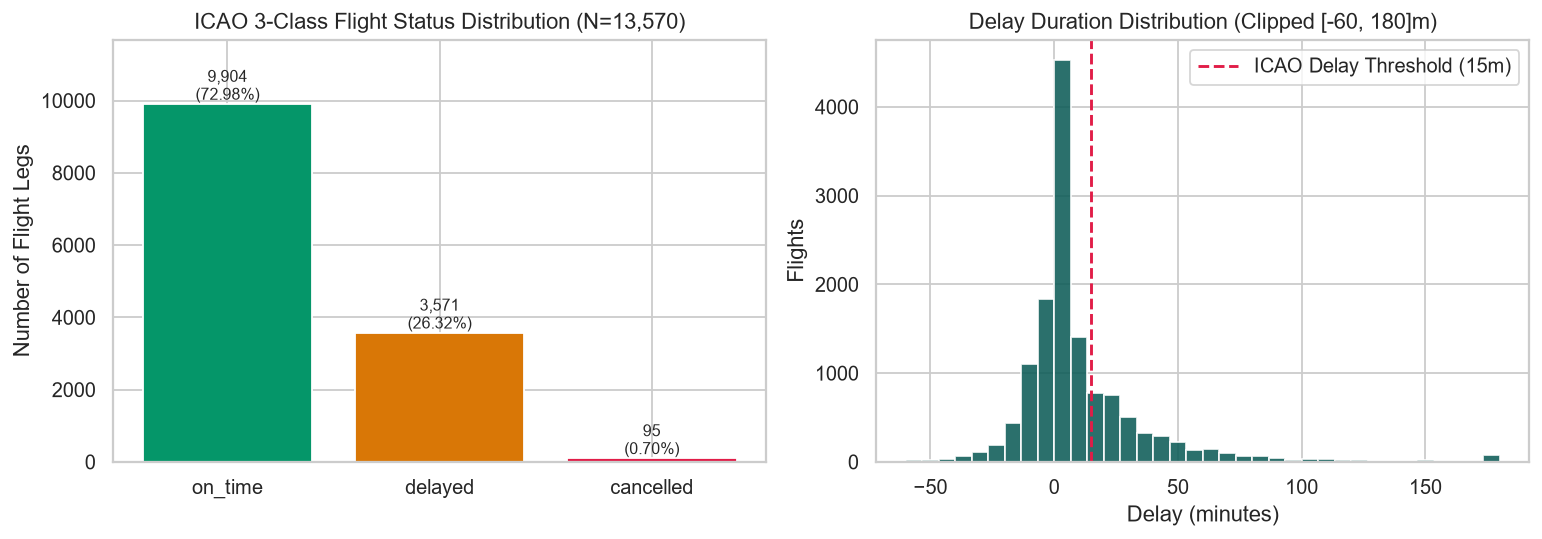

In [2]:
# Visualization 1 & 2: Flight Status Distribution & Delay Duration Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

st_cnt = gold["status_clean"].value_counts().reindex(["on_time", "delayed", "cancelled"])
colors = ["#059669", "#d97706", "#e11d48"]
axes[0].bar(st_cnt.index, st_cnt.values, color=colors)
for i, v in enumerate(st_cnt.values):
    axes[0].text(i, v + 120, f"{v:,}\n({v/len(gold)*100:.2f}%)", ha="center", fontsize=9)
axes[0].set_title("ICAO 3-Class Flight Status Distribution (N=13,570)")
axes[0].set_ylabel("Number of Flight Legs")
axes[0].set_ylim(0, st_cnt.max() * 1.18)

delays = pd.to_numeric(gold["delay_min"], errors="coerce").dropna().clip(-60, 180)
axes[1].hist(delays, bins=36, color="#0d5c58", edgecolor="white", alpha=0.88)
axes[1].axvline(15, color="#e11d48", linestyle="--", linewidth=1.6, label="ICAO Delay Threshold (15m)")
axes[1].set_title("Delay Duration Distribution (Clipped [-60, 180]m)")
axes[1].set_xlabel("Delay (minutes)")
axes[1].set_ylabel("Flights")
axes[1].legend()

fig.tight_layout()
plt.show()

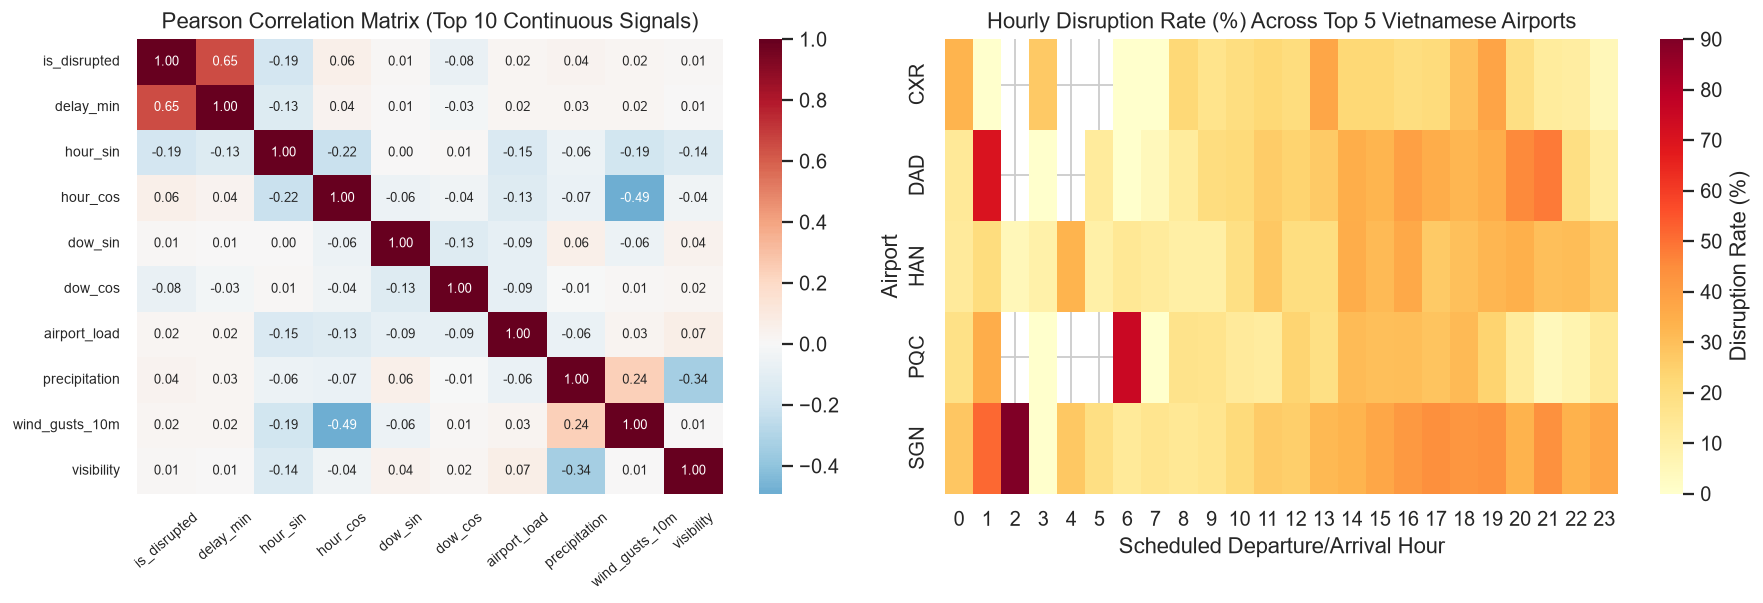

In [3]:
# Visualization 3 & 4: Pearson Correlation Heatmap & Hourly Delay Rate Heatmap (Airport x Hour)
corr_info = eda["correlation_and_association"]
cols_hm = corr_info["matrix_columns"][:10]
mat_p = np.array(corr_info["pearson_matrix"])[:10, :10]

gold_hm = gold[gold["airport"].isin(["SGN", "HAN", "DAD", "CXR", "PQC"])].copy()
gold_hm["hour"] = pd.to_numeric(gold_hm["scheduled_time"].astype(str).str.extract(r"^(\d{1,2})")[0], errors="coerce")
gold_hm = gold_hm[gold_hm["hour"].notna()].copy()
gold_hm["hour"] = gold_hm["hour"].astype(int)
gold_hm["is_bad"] = gold_hm["status_clean"].isin(["delayed", "cancelled"]).astype(float) * 100.0
piv = gold_hm.pivot_table(index="airport", columns="hour", values="is_bad", aggfunc="mean")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})
sns.heatmap(mat_p, xticklabels=cols_hm, yticklabels=cols_hm, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[0])
axes[0].set_title("Pearson Correlation Matrix (Top 10 Continuous Signals)")
axes[0].tick_params(axis="x", rotation=40, labelsize=8)
axes[0].tick_params(axis="y", labelsize=8)

sns.heatmap(piv, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Disruption Rate (%)"})
axes[1].set_title("Hourly Disruption Rate (%) Across Top 5 Vietnamese Airports")
axes[1].set_xlabel("Scheduled Departure/Arrival Hour")
axes[1].set_ylabel("Airport")

fig.tight_layout()
plt.show()